# Resultados phantom revisados — UG con $(Q=\alpha\rho^\beta)$

Este notebook **no vuelve a ejecutar el barrido ODE**. Trabaja únicamente con
`data/processed/phantom_results_revised.csv` y presenta los resultados consolidados
para exposición.

Modelo:
$
p=\omega\rho,\qquad Q=\alpha\rho^\beta,\qquad \omega<-1,
$
$
3H^2=\rho+\alpha\rho^\beta,\qquad
\dot\rho=-\frac{3H(1+\omega)\rho}
{1+\alpha\beta\rho^{\beta-1}},
\qquad
\dot H=-\frac{1+\omega}{2}\rho.
$


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd

CURRENT_PATH = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (CURRENT_PATH, *CURRENT_PATH.parents)
        if (candidate / "src").is_dir() and (candidate / "data").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "phantom_results_revised.csv"
FIG_DIR = PROJECT_ROOT / "results" / "figures" / "barotropic" / "phantom_scan"
TABLE_DIR = PROJECT_ROOT / "results" / "tables" / "phantom"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró {DATA_PATH.relative_to(PROJECT_ROOT)}")

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
})

df = pd.read_csv(DATA_PATH)
print("CSV:", DATA_PATH.relative_to(PROJECT_ROOT))
print("Filas phantom:", len(df))
print("Valores de omega:", sorted(df["omega"].unique()))


CSV: data/processed/phantom_results_revised.csv
Filas phantom: 2325
Valores de omega: [np.float64(-1.4), np.float64(-1.2), np.float64(-1.05)]


## 1. Conteos finales por régimen

In [2]:
counts = (
    df.groupby(["omega", "final_behavior"])
    .size()
    .rename("count")
    .reset_index()
)
counts_path = TABLE_DIR / "behavior_counts.csv"
counts.to_csv(counts_path, index=False)
display(counts)
print("Tabla guardada en:", counts_path.relative_to(PROJECT_ROOT))


,omega,final_behavior,count
0,-1.40,diffusion_driven_infinite_time_rip,158
1,-1.40,little_rip,140
2,-1.40,type_i_big_rip,417
3,-1.40,type_iv_D_boundary,60
4,-1.20,diffusion_driven_infinite_time_rip,158
5,-1.20,little_rip,140
6,-1.20,type_i_big_rip,417
7,-1.20,type_iv_D_boundary,60
8,-1.05,diffusion_driven_infinite_time_rip,158
9,-1.05,little_rip,140


Tabla guardada en: results/tables/phantom/behavior_counts.csv


## 2. Correcciones analíticas al diagnóstico puramente numérico

In [3]:
corrected = df.loc[
    df["analytic_correction"].fillna("").ne(""),
    [
        "omega", "alpha", "beta", "numerical_label_original",
        "final_behavior", "analytic_correction",
    ],
].copy()
corrected_path = TABLE_DIR / "analytic_corrections.csv"
corrected.to_csv(corrected_path, index=False)
print("Puntos corregidos:", len(corrected))
display(corrected.head(50))
print("Tabla guardada en:", corrected_path.relative_to(PROJECT_ROOT))


Puntos corregidos: 88


,omega,alpha,beta,numerical_label_original,final_behavior,analytic_correction
212,-1.4,1.550000,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
213,-1.4,1.754167,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
214,-1.4,1.958333,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
215,-1.4,2.162500,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
216,-1.4,2.366667,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
217,-1.4,2.570833,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
218,-1.4,2.775000,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
219,-1.4,2.979167,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
220,-1.4,3.183333,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
221,-1.4,3.387500,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...


Tabla guardada en: results/tables/phantom/analytic_corrections.csv


## 3. Tabla de regiones

Para $(\rho_0=1)$:

$
\beta<0,\ \alpha>0,\ D_0=1+\alpha\beta<0
\Rightarrow
\text{rip asintótico dominado por difusión}.
$

$
\alpha<0,\ \beta>1
\Rightarrow
D(\rho_D)=0
\Rightarrow
\text{Tipo IV}.
$

$
\alpha>0,\ \beta\ge2
\Rightarrow
\text{Little Rip}.
$

Las ramas phantom físicas restantes terminan en Big Rip.


## 4. Mapa revisado para $\omega$ = -1.2

Figura guardada en: results/figures/barotropic/phantom_scan/phantom_map_omega_m1p2.pdf


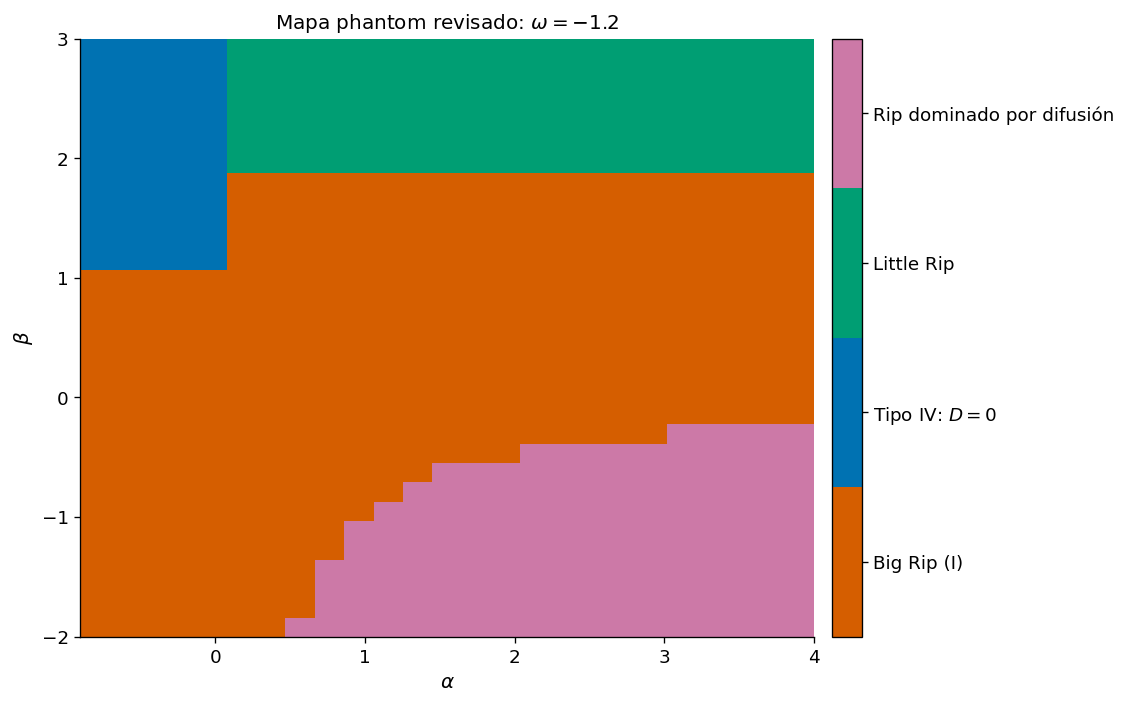

In [4]:
omega = -1.2
subset = df[np.isclose(df["omega"], omega)].copy()
labels = [
    "type_i_big_rip",
    "type_iv_D_boundary",
    "little_rip",
    "diffusion_driven_infinite_time_rip",
]
label_to_code = {label: index for index, label in enumerate(labels)}
matrix = (
    subset.pivot(index="beta", columns="alpha", values="final_behavior")
    .sort_index()
    .sort_index(axis=1)
)
encoded = matrix.map(label_to_code.get).to_numpy(dtype=float)
alphas = matrix.columns.to_numpy(dtype=float)
betas = matrix.index.to_numpy(dtype=float)

colors = ["#D55E00", "#0072B2", "#009E73", "#CC79A7"]
fig, ax = plt.subplots(figsize=(9.5, 6.0))
image = ax.imshow(
    encoded,
    origin="lower",
    aspect="auto",
    extent=[alphas.min(), alphas.max(), betas.min(), betas.max()],
    interpolation="nearest",
    cmap=ListedColormap(colors),
    vmin=-0.5,
    vmax=len(labels) - 0.5,
)
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$\beta$")
ax.set_title(r"Mapa phantom revisado: $\omega=-1.2$")
colorbar = fig.colorbar(image, ax=ax, ticks=range(len(labels)), pad=0.02)
colorbar.set_ticklabels([
    "Big Rip (I)",
    r"Tipo IV: $D=0$",
    "Little Rip",
    "Rip dominado por difusión",
])
fig.tight_layout()

for suffix in (".pdf", ".png"):
    fig.savefig(FIG_DIR / f"phantom_map_omega_m1p2{suffix}", bbox_inches="tight")
print(
    "Figura guardada en:",
    (FIG_DIR / "phantom_map_omega_m1p2.pdf").relative_to(PROJECT_ROOT),
)
plt.show()
plt.close(fig)


## 5. Frontera $(\beta=2)$

Para $(\alpha>0,\beta>1,\rho\to\infty)$,
$
\dot\rho\sim
\frac{\sqrt3\,\gamma}{\beta\sqrt{\alpha}}
\rho^{2-\beta/2}.
$

Por lo tanto:
$
\beta<2\Rightarrow t_s<\infty,
\qquad
\beta\ge2\Rightarrow t\to\infty.
$


In [5]:
comp = df[
    (df["alpha"] > 0)
    & (df["rho_limit"] == "diverges")
    & (df["finite_time"].notna())
].copy()

comp["prediction_finite"] = comp["beta"] < 2
comp["observed_finite"] = comp["finite_time"].astype(bool)
comp["agreement"] = (
    comp["prediction_finite"]
    == comp["observed_finite"]
)

print("Puntos comparados:", len(comp))
print("Acuerdo:", comp["agreement"].mean())
print("Desacuerdos:", (~comp["agreement"]).sum())


Puntos comparados: 1386
Acuerdo: 1.0
Desacuerdos: 0


## 6. F2

$
(\omega,\alpha,\beta)=(-1.2,4,-1),
\qquad
Q=\frac4\rho,
\qquad
D=1-\frac4{\rho^2}.
$

Con $(\rho_0=1)$,
$
D_0=-3<0
\quad\Rightarrow\quad
\dot\rho<0.
$

Así:
$
\rho\to0,\quad
Q\to\infty,\quad
H\to\infty,\quad
\dot H\to0^+,\quad
a\to\infty,
\quad t\to\infty.
$

La relación exacta es
$
a(\rho)=
\rho^{5/3}
\exp\left[
\frac{10}{3}
(\rho^{-2}-1)
\right].
$

Asintóticamente:
$
\rho\sim(0.2598t)^{-2/3},
\quad
H\sim0.737t^{1/3},
\quad
\dot H\sim0.246t^{-2/3},
\quad
\ln a\sim0.553t^{4/3}.
$


In [6]:
f2 = df[
    np.isclose(df["omega"], -1.2)
    & np.isclose(df["alpha"], 4.0)
    & np.isclose(df["beta"], -1.0)
]

display(
    f2[
        [
            "omega",
            "alpha",
            "beta",
            "D0",
            "numerical_label_original",
            "final_behavior",
            "time_limit",
            "rho_limit",
            "a_limit",
            "H_limit",
            "Hdot_limit",
            "confidence",
        ]
    ]
)


,omega,alpha,beta,D0,numerical_label_original,final_behavior,time_limit,rho_limit,a_limit,H_limit,Hdot_limit,confidence
949,-1.2,4.0,-1.0,-3.0,diffusion_driven_infinite_time_rip,diffusion_driven_infinite_time_rip,infinite,zero,diverges,diverges,zero,0.95


## 7. Principales conclusiones

1. El régimen phantom presenta cuatro destinos robustos.
2. La frontera $(\beta=2)$ separa Big Rip y Little Rip para $(\alpha>0)$.
3. $(\alpha<0,\beta>1)$ conduce a una frontera $(D=0)$ de Tipo IV.
4. Existe una región completa $(\beta<0,\alpha>0,D_0<0)$ en la cual
   $(\rho\to0)$ pero la difusión produce $(Q,H,a\to\infty)$.
5. F2 es un representante particularmente limpio de esta región.
6. Por ahora la región F2 se llamara **régimen asintótico dominado por difusión**
   o **diffusion-driven infinite-time rip**, aún no se debe clasificar como una nueva singularidad.
